# Supplementary Figure S11d. Neuron-responsive astrocyte genes in the co-culture experiment

DESeq2 differential expression of astrocyte genes between neuron-astrocyte co-culture and astrocyte mono-culture (astrocyte reads only; mouse genes). x-axis: DESeq2 log2 fold change (co-culture vs mono-culture); y-axis: $-\log_{10}$ of the BH-adjusted p-value. All 3587 genes shown are neuron-responsive (padj < 0.01, dashed line). Red: the 22 genes of the GDA-colocalized astrocyte *trans*-eProgram 80 whose human orthologs are in the co-culture astrocyte gene set (GSTM3 corresponds to mouse *Gstm5*); blue: other neuron-responsive astrocyte genes. As in the published panel the view is limited to |log2FC| <= 2 and $-\log_{10}$ padj <= 20 (29 and 78 blue genes fall outside; no red gene does).

Note: only the DE-gene table (padj < 0.01) is available, so the non-significant background genes drawn below the threshold in the published panel are not shown.

Input: `data/Figure_S11d_coculture_volcano.rds`


In [1]:
library(ggplot2)
library(ggrepel)
dat <- readRDS("data/Figure_S11d_coculture_volcano.rds")
de <- dat$de
nrow(de)
de[de$in_GDA_program80_overlap, c("mouse_gene", "human_symbol", "log2_fold_change", "padj", "neg_log10_padj")]

[1] 3587

,mouse_gene,human_symbol,log2_fold_change,padj,neg_log10_padj
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
27,Araf,ARAF,0.23957633,4.870000e-06,5.312471
119,Gstm5,GSTM3,0.20931164,8.860000e-08,7.052566
151,Tbl2,TBL2,-0.22016629,7.072930e-04,3.150401
234,Slc3a2,SLC3A2,-0.32905489,1.440000e-06,5.841638
277,Ptgds,PTGDS,0.11567298,1.260000e-05,4.899629
352,Kpna2,KPNA2,0.09182889,5.507087e-03,2.259078
465,Llgl1,LLGL1,0.22145398,8.330000e-11,10.079355
496,Grin2c,GRIN2C,0.57833218,2.050000e-08,7.688246
592,Cxcl14,CXCL14,-0.09299464,1.020000e-08,7.991400


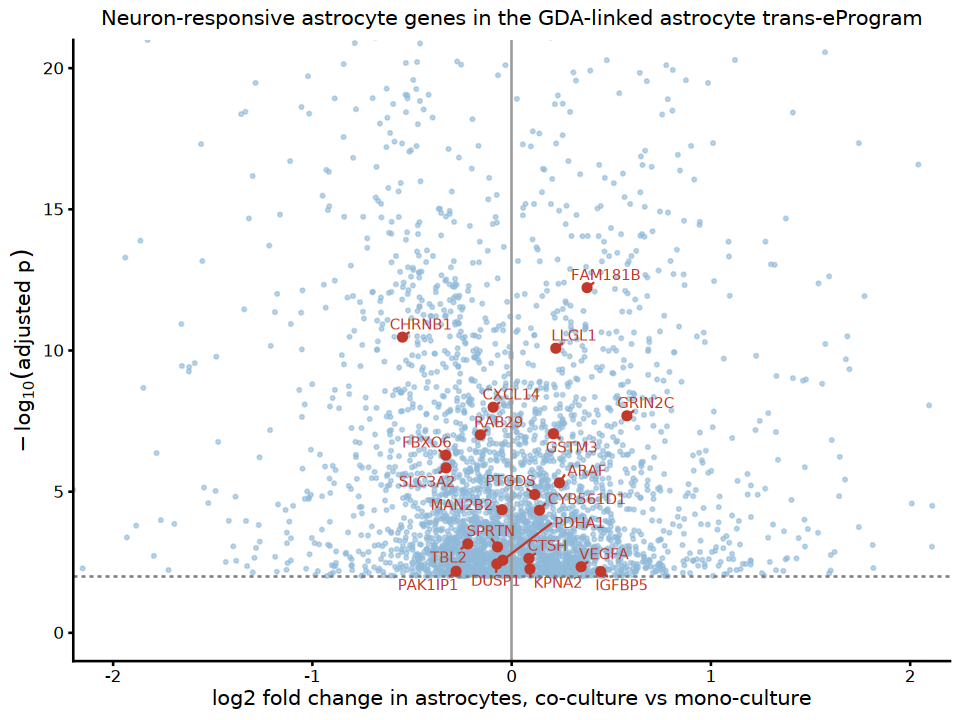

In [2]:
red <- de[de$in_GDA_program80_overlap, ]
p <- ggplot(de, aes(log2_fold_change, neg_log10_padj)) +
  geom_point(data = de[!de$in_GDA_program80_overlap, ], colour = "#8FB9D9", size = 0.6, alpha = 0.6) +
  geom_hline(yintercept = 2, linetype = 2, colour = "grey50") +
  geom_vline(xintercept = 0, colour = "grey60") +
  geom_point(data = red, colour = "#C0392B", size = 2) +
  geom_text_repel(data = red, aes(label = human_symbol), colour = "#C0392B", size = 3,
                  max.overlaps = Inf, seed = 1, min.segment.length = 0) +
  coord_cartesian(xlim = c(-2, 2), ylim = c(0, 20)) +
  labs(title = "Neuron-responsive astrocyte genes in the GDA-linked astrocyte trans-eProgram",
       x = "log2 fold change in astrocytes, co-culture vs mono-culture",
       y = expression(-log[10](adjusted~italic(p)))) +
  theme_classic(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5, size = 12))
options(repr.plot.width = 8, repr.plot.height = 6)
p